FIRST FIVE RECORDS
      date workout_type muscle_group  duration_min  exercises  sets  reps  weight_kg
2026-10-01         Push        Chest            60          4    12    10         40
2026-10-02         Pull         Back            55          4    12    10         45
2026-10-03         Legs         Legs            70          5    15    10         60
2026-10-05         Push    Shoulders            50          3    12    10         12
2026-10-06         Pull         Back            60          4    10    10         50

DATASET SIZE: (12, 8)

MISSING VALUES
date            0
workout_type    0
muscle_group    0
duration_min    0
exercises       0
sets            0
reps            0
weight_kg       0
dtype: int64

GYM PERFORMANCE SUMMARY
Total sessions: 12
Total training time: 710 minutes
Average session duration: 59.17 minutes

SESSIONS BY WORKOUT TYPE
workout_type
Push    4
Pull    4
Legs    4
Name: count, dtype: int64

SESSIONS BY MUSCLE GROUP
muscle_group
Legs         4
Back     

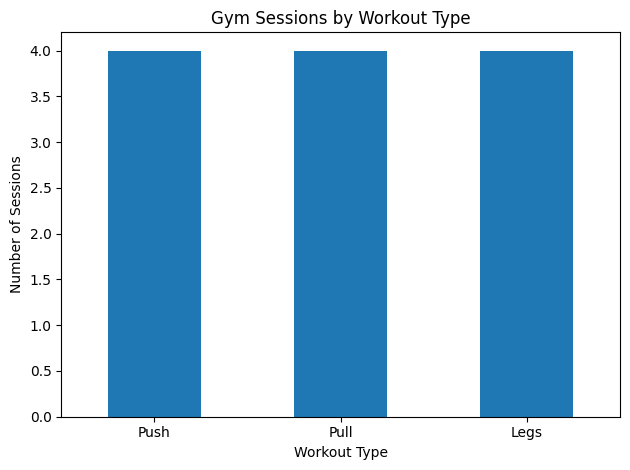

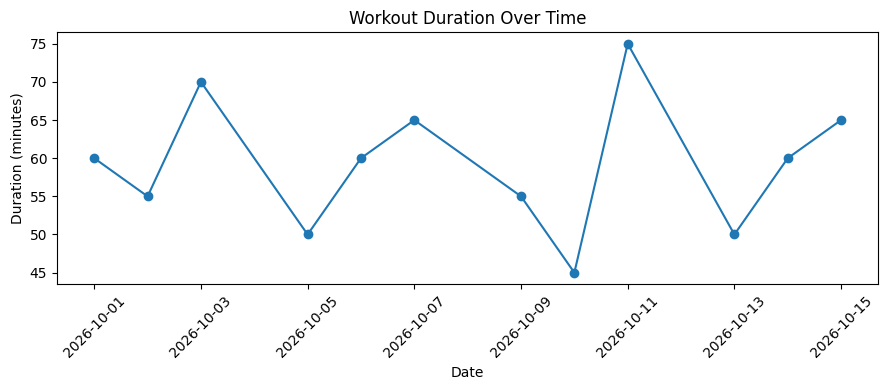


ANALYSIS COMPLETED SUCCESSFULLY


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

# Sample gym dataset
csv_data = """date,workout_type,muscle_group,duration_min,exercises,sets,reps,weight_kg
2026-10-01,Push,Chest,60,4,12,10,40
2026-10-02,Pull,Back,55,4,12,10,45
2026-10-03,Legs,Legs,70,5,15,10,60
2026-10-05,Push,Shoulders,50,3,12,10,12
2026-10-06,Pull,Back,60,4,10,10,50
2026-10-07,Legs,Legs,65,5,12,10,70
2026-10-09,Push,Chest,55,4,10,10,45
2026-10-10,Pull,Biceps,45,3,12,10,12
2026-10-11,Legs,Legs,75,5,10,10,80
2026-10-13,Push,Shoulders,50,4,12,10,14
2026-10-14,Pull,Back,60,4,10,10,55
2026-10-15,Legs,Legs,65,5,12,10,75
"""

# Load the data without downloading anything
df = pd.read_csv(StringIO(csv_data))
df["date"] = pd.to_datetime(df["date"])

# Inspect the dataset
print("FIRST FIVE RECORDS")
print(df.head().to_string(index=False))

print("\nDATASET SIZE:", df.shape)
print("\nMISSING VALUES")
print(df.isnull().sum())

# Calculate key metrics
print("\nGYM PERFORMANCE SUMMARY")
print("Total sessions:", len(df))
print("Total training time:", df["duration_min"].sum(), "minutes")
print("Average session duration:",
      round(df["duration_min"].mean(), 2), "minutes")

print("\nSESSIONS BY WORKOUT TYPE")
print(df["workout_type"].value_counts())

print("\nSESSIONS BY MUSCLE GROUP")
print(df["muscle_group"].value_counts())

# Chart 1: Workout types
df["workout_type"].value_counts().plot(kind="bar")
plt.title("Gym Sessions by Workout Type")
plt.xlabel("Workout Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 2: Workout duration over time
plt.figure(figsize=(9, 4))
plt.plot(df["date"], df["duration_min"], marker="o")
plt.title("Workout Duration Over Time")
plt.xlabel("Date")
plt.ylabel("Duration (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nANALYSIS COMPLETED SUCCESSFULLY")


# Gym Performance & Training Analytics

## Project Overview
This project analyses sample gym workout data using Python, Pandas, Matplotlib, and SQL.

## Objectives
- Analyse workout frequency and duration.
- Compare training time across muscle groups.
- Calculate estimated training volume.
- Use SQL to summarise workouts and identify the longest sessions.
- Visualise results using charts.

## Tools Used
- Python
- Pandas
- Matplotlib
- SQLite
- Google Colab

## Dataset
The dataset contains 12 illustrative workout records with dates,
workout types, muscle groups, session duration, sets, reps, and weight.

## Current Progress
- [x] Dataset created and loaded
- [x] Workout summaries calculated
- [x] Charts generated
- [x] SQL queries executed
- [ ] Project files published on GitHub
- [ ] Power BI dashboard created

## Important Note
The data is illustrative and does not represent actual gym members
or personal workout measurements.


TOTAL TRAINING TIME BY MUSCLE GROUP
muscle_group
Legs         275
Back         175
Chest        115
Shoulders    100
Biceps        45
Name: duration_min, dtype: int64


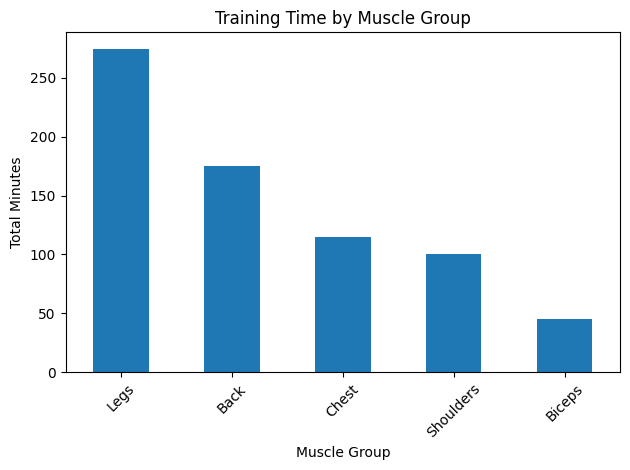


WORKOUT CONSISTENCY
Days with recorded workouts: 12
Total workout sessions: 12
Average session duration: 59.2 minutes


In [2]:

# GYM ANALYTICS: MUSCLE GROUP ANALYSIS

# Total training time by muscle group
muscle_time = (
    df.groupby("muscle_group")["duration_min"]
    .sum()
    .sort_values(ascending=False)
)

print("TOTAL TRAINING TIME BY MUSCLE GROUP")
print(muscle_time)

# Create a chart
muscle_time.plot(kind="bar")
plt.title("Training Time by Muscle Group")
plt.xlabel("Muscle Group")
plt.ylabel("Total Minutes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate workout consistency
df["date"] = pd.to_datetime(df["date"])
unique_days = df["date"].nunique()

print("\nWORKOUT CONSISTENCY")
print("Days with recorded workouts:", unique_days)
print("Total workout sessions:", len(df))
print(
    "Average session duration:",
    round(df["duration_min"].mean(), 1),
    "minutes"
)


TOTAL TRAINING VOLUME BY MUSCLE GROUP
muscle_group
Legs         34400
Back         15900
Chest         9300
Shoulders     3120
Biceps        1440
Name: volume_kg, dtype: int64


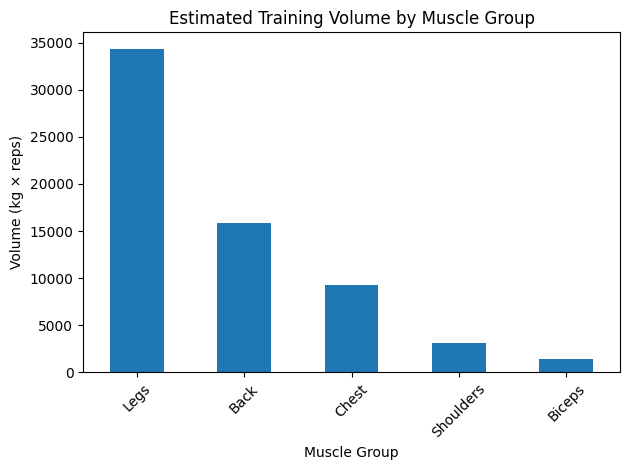

In [3]:

# GYM ANALYTICS: TRAINING VOLUME

# Estimate volume using the recorded weight, sets and reps.
# This assumes each row represents one exercise entry.
df["volume_kg"] = df["weight_kg"] * df["sets"] * df["reps"]

print("TOTAL TRAINING VOLUME BY MUSCLE GROUP")
print(
    df.groupby("muscle_group")["volume_kg"]
    .sum()
    .sort_values(ascending=False)
)

# Plot the results
volume = (
    df.groupby("muscle_group")["volume_kg"]
    .sum()
    .sort_values(ascending=False)
)

volume.plot(kind="bar")
plt.title("Estimated Training Volume by Muscle Group")
plt.xlabel("Muscle Group")
plt.ylabel("Volume (kg × reps)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [4]:

import sqlite3
import pandas as pd

# Create an in-memory SQL database
conn = sqlite3.connect(":memory:")

# Copy our DataFrame into a SQL table
df.to_sql("workouts", conn, if_exists="replace", index=False)

# Query 1: Count sessions by workout type
query1 = """
SELECT workout_type,
       COUNT(*) AS total_sessions,
       ROUND(AVG(duration_min), 1) AS avg_duration_min
FROM workouts
GROUP BY workout_type
ORDER BY total_sessions DESC;
"""

print("SESSIONS BY WORKOUT TYPE")
print(pd.read_sql_query(query1, conn).to_string(index=False))

# Query 2: Training volume by muscle group
query2 = """
SELECT muscle_group,
       SUM(volume_kg) AS total_volume
FROM workouts
GROUP BY muscle_group
ORDER BY total_volume DESC;
"""

print("\nTRAINING VOLUME BY MUSCLE GROUP")
print(pd.read_sql_query(query2, conn).to_string(index=False))

# Query 3: Longest workout sessions
query3 = """
SELECT date, workout_type, duration_min
FROM workouts
ORDER BY duration_min DESC
LIMIT 5;
"""

print("\nTOP 5 LONGEST SESSIONS")
print(pd.read_sql_query(query3, conn).to_string(index=False))

conn.close()


SESSIONS BY WORKOUT TYPE
workout_type  total_sessions  avg_duration_min
        Push               4              53.8
        Pull               4              55.0
        Legs               4              68.8

TRAINING VOLUME BY MUSCLE GROUP
muscle_group  total_volume
        Legs         34400
        Back         15900
       Chest          9300
   Shoulders          3120
      Biceps          1440

TOP 5 LONGEST SESSIONS
               date workout_type  duration_min
2026-10-11 00:00:00         Legs            75
2026-10-03 00:00:00         Legs            70
2026-10-07 00:00:00         Legs            65
2026-10-15 00:00:00         Legs            65
2026-10-01 00:00:00         Push            60
